# Lab 3-05：重排序與查詢改寫——先撈多一點，再仔細挑

**目標**：在混合檢索後面接一個 cross-encoder 重排序模型，再試三種前處理／後處理：查詢改寫、HyDE、small-to-big。

**你會學到**
- 相似不等於相關：embedding（雙塔）分開讀問題和段落，cross-encoder 把兩者一起讀
- 兩階段檢索：便宜的方法撈 20 塊，貴的模型挑 3 塊
- 查詢改寫與 HyDE：問題寫得不好時，讓 LLM 先幫它換個說法
- small-to-big：用小塊找、用大塊回答

**前置**：Lab 3-04。第一次執行會下載 `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1`（約 470MB，多語言、CPU 也跑得動）。原理見 `00_concepts.md` 第 5 節。

**對應投影片**：「重排漏斗與模型」「雙塔與 Cross-Encoder」「父子片段：小的找、大的回」「文件轉問答：多開搜尋入口」「選型：Embedding 與重排」

![重排前後名次](images/rerank_rank_change.jpg)

*圖：左邊是向量檢索的名次，中間 cross-encoder 把「問題＋片段」一起讀、重新打分，右邊是新名次。朱紅線是原本第 5 名、重排後變第 1 名的那一塊。*

## Step 1：準備混合檢索

跟 Lab 3-04 一樣：Chroma 一路、BM25 一路、RRF 合併。這次每路撈 20 塊，當作重排序的候選。

In [1]:
from rag_utils import (BM25Index, build_collection, chunk_docs, dedup_docs, hit_at_k,
                       load_docs, load_qa, reciprocal_rank, rrf, vector_search)

docs = load_docs()
qa = load_qa()
chunks = chunk_docs(docs)
text_of = {c.chunk_id: c.text for c in chunks}
collection = build_collection(chunks, "rerank")
bm25 = BM25Index(chunks)

CURRENT = {"status": "current"}
allowed = {c.chunk_id for c in chunks if c.meta["status"] == "current"}


def hybrid(query: str, k: int = 20) -> list[str]:
    return rrf([bm25.search(query, k, allowed), vector_search(collection, query, k, CURRENT)])[:k]


print(hybrid("TP-4021 可以重試嗎？")[:5])

['rb-tp-4012-3ds-timeout#3', 'svc-tidepay#3', 'svc-breakwater#4', 'pm-2026-0921-mq-lag#2', 'rb-auth-1109-jwks#2']


## Step 2：相似 ≠ 相關

三段候選文字，問題問的是「TP-4021 能不能重試」。A 句型跟問題幾乎一樣，但講的是另一個錯誤碼；B 才回答了問題。

In [2]:
import numpy as np

from course_utils.llm import embed

question = "TP-4021 可以重試嗎？"
candidates = {
    "A 句型很像、代碼不同": "TP-4012 可以重試嗎？可以，請使用者重新付款即可。",
    "B 真正的答案": "冪等鍵衝突（TP-4021）是呼叫端程式錯誤，不可重試，要查呼叫端。",
    "C 無關": "breakwater 的限流是每分鐘 600 次。",
}
vecs = np.array(embed([question, *candidates.values()]))
vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)
for name, s in zip(candidates, vecs[1:] @ vecs[0]):
    print(f"embedding cosine {s:.3f}  {name}")

embedding cosine 0.770  A 句型很像、代碼不同
embedding cosine 0.642  B 真正的答案
embedding cosine 0.438  C 無關


## Step 3：cross-encoder 把問題和段落一起讀

embedding 模型是「雙塔」：問題和段落各自變成向量，最後才比距離，彼此看不到對方。
cross-encoder 把「問題＋段落」接成一句話送進同一個 transformer，attention 可以直接比對兩邊的每個字，所以更準，但每一對都要跑一次模型，很慢。

`sentence-transformers` 的 `CrossEncoder` 一行載入，`predict` 吃 (問題, 段落) 配對清單，回傳相關性分數（logit，越大越相關）。

In [3]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
scores = reranker.predict([(question, text) for text in candidates.values()])
for name, s in zip(candidates, scores):
    print(f"cross-encoder {s:7.2f}  {name}")

cross-encoder    4.44  A 句型很像、代碼不同
cross-encoder   10.31  B 真正的答案
cross-encoder   -5.87  C 無關


embedding 覺得 A 最像；cross-encoder 才看出 B 真正回答了問題。

## Step 4：兩階段——混合檢索撈 20 塊，cross-encoder 挑前幾名

拿一題 Lab 3-04 裡混合檢索也排錯的題目，看重排前後的名次。

In [4]:
def rerank(query: str, chunk_ids: list[str]) -> list[str]:
    scores = reranker.predict([(query, text_of[c]) for c in chunk_ids])
    return [chunk_ids[i] for i in np.argsort(-scores)]


q = "使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？"
before = hybrid(q)
after = rerank(q, before)
print("重排前：", before[:5])
print("重排後：", after[:5])

重排前： ['rb-tp-4012-3ds-timeout#0', 'svc-tidepay#3', 'rb-tp-4012-3ds-timeout#1', 'svc-tidepay#0', 'pm-2026-0921-mq-lag#1']
重排後： ['pm-2026-0314-double-charge#2', 'pm-2026-0314-double-charge#3', 'svc-tidepay#2', 'pm-2026-0314-double-charge#0', 'pm-2026-0314-double-charge#1']


## Step 5：畫出名次變化

左邊是混合檢索的名次，右邊是重排後的名次，同一塊用線連起來。紅線是標準答案所在的文件。

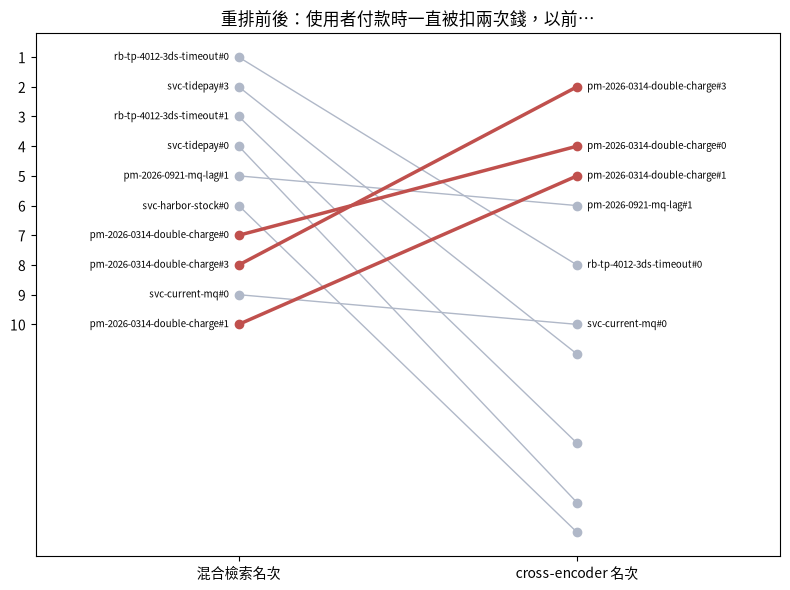

In [5]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

gold = next(x for x in qa if x["question"] == q)["doc_ids"]
top_n = 10
plt.figure(figsize=(8, 6))
for cid in before[:top_n]:
    y0 = before.index(cid)
    y1 = after.index(cid)
    is_gold = cid.split("#")[0] in gold
    plt.plot([0, 1], [y0, y1], marker="o", color="#c0504d" if is_gold else "#b0b8c8", lw=2.5 if is_gold else 1)
    plt.text(-0.03, y0, cid, ha="right", va="center", fontsize=7)
    if y1 < top_n:
        plt.text(1.03, y1, cid, ha="left", va="center", fontsize=7)
plt.gca().invert_yaxis()
plt.xticks([0, 1], ["混合檢索名次", "cross-encoder 名次"])
plt.yticks(range(top_n), [str(i + 1) for i in range(top_n)])
plt.xlim(-0.6, 1.6)
plt.title(f"重排前後：{q[:16]}…")
plt.tight_layout()
plt.show()

## Step 6：整份題庫——重排值不值得？

比較「混合檢索」與「混合檢索＋重排」的 Hit@1、MRR，順便量每題花多少時間。

In [6]:
import time


def evaluate(fn) -> dict:
    hit1, hit3, rr, secs = [], [], [], []
    for x in qa:
        t = time.time()
        ranked = dedup_docs(fn(x["question"]))
        secs.append(time.time() - t)
        hit1.append(hit_at_k(ranked, x["doc_ids"], 1))
        hit3.append(hit_at_k(ranked, x["doc_ids"], 3))
        rr.append(reciprocal_rank(ranked, x["doc_ids"]))
    return {"Hit@1": np.mean(hit1), "Hit@3": np.mean(hit3), "MRR": np.mean(rr), "秒/題": np.mean(secs)}


results = {
    "向量": evaluate(lambda s: vector_search(collection, s, 20, CURRENT)),
    "混合 RRF": evaluate(hybrid),
    "混合＋重排": evaluate(lambda s: rerank(s, hybrid(s))),
}
for name, r in results.items():
    print(f"{name:<8} " + "  ".join(f"{k} {v:.2f}" for k, v in r.items()))

向量       Hit@1 0.89  Hit@3 1.00  MRR 0.95  秒/題 0.02
混合 RRF   Hit@1 0.92  Hit@3 0.97  MRR 0.95  秒/題 0.02
混合＋重排    Hit@1 0.97  Hit@3 1.00  MRR 0.99  秒/題 0.10


重排多花的時間是 cross-encoder 跑 20 對的時間。候選越多越準、也越慢；實務上召回 20～50 塊、重排後留 3～5 塊塞進 prompt。

## Step 7：查詢改寫——讓 LLM 把口語問題換成文件的說法

使用者說「錢被扣兩次」，文件寫「重複扣款」。請 LLM 把問題改寫成幾個關鍵字查詢，每個都去檢索，再用 RRF 合併（cookbooks 607 的 query expansion）。

`rag_utils.ask` 就是 `chat` 加上較長的逾時與重試（Ollama 被多人共用時偶爾會逾時）。

In [7]:
from rag_utils import ask as chat

REWRITE = """你是公司內部技術文件的搜尋助手。把使用者的問題改寫成 3 個適合搜尋技術文件的短查詢，
使用工程師會用的術語（例如錯誤碼、服務名、專有名詞）。一行一個，不要編號，不要解釋。

問題：{q}"""


def rewrite(q: str) -> list[str]:
    lines = chat([{"role": "user", "content": REWRITE.format(q=q)}]).splitlines()
    return [l.strip("-•· 0123456789.") for l in lines if l.strip()][:3]


for q in ["使用者付款時一直被扣兩次錢，以前發生過嗎？", "大家突然一直被登出"]:
    print(q, "→", rewrite(q))

（第 1 次呼叫失敗，5 秒後重試：所有端點都失敗：
local: Request timed out.）
使用者付款時一直被扣兩次錢，以前發生過嗎？ → ['使用者付款異常扣款紀錄查詢', '過去使用者付款異常事件查詢', '使用者雙重扣款記錄查詢']
大家突然一直被登出 → ['大家突然一直被登出 登录失败 登出事件']


In [8]:
def multi_query(q: str, k: int = 20) -> list[str]:
    queries = [q, *rewrite(q)]
    return rrf([hybrid(x, k) for x in queries])[:k]


q = "使用者付款時一直被扣兩次錢，以前發生過嗎？"
print("原問題：", dedup_docs(hybrid(q))[:3])
print("改寫後：", dedup_docs(multi_query(q))[:3])

原問題： ['rb-tp-4012-3ds-timeout', 'svc-tidepay', 'pm-2026-0314-double-charge']
改寫後： ['pm-2026-0314-double-charge', 'svc-tidepay', 'rb-tp-4012-3ds-timeout']


## Step 8：HyDE——先讓 LLM 編一個答案，再拿答案去找

HyDE（Hypothetical Document Embeddings）：問題很短，跟文件段落長得不像；但「一段假答案」跟真文件長得很像。
答案內容可能是錯的，沒關係——我們只用它的**樣子**去做向量檢索，最後回答還是根據真文件。

In [9]:
HYDE = "你是海風科技的工程師。用 3～4 句話寫一段內部技術文件，回答下面的問題。不知道細節就合理推測。\n\n問題：{q}"

q = "出貨通知寄得很慢，要怎麼加速消化積壓的訊息？"
fake = chat([{"role": "user", "content": HYDE.format(q=q)}])
print("假答案：", fake)
print()
print("用問題找：", dedup_docs(vector_search(collection, q, 10, CURRENT))[:3])
print("用假答案找：", dedup_docs(vector_search(collection, fake, 10, CURRENT))[:3])

假答案： 在處理出貨通知時，我們發現由於系統處理效率低下，導致積壓的訊息無法及時消化。為此，我們計劃優化後端處理流程，增加處理訊息的線程數量，並優化數據庫查詢效率，從而提高系統處理速度，以加速消化積壓的訊息。此外，我們還會定期進行系統性能調優，確保系統在高負載情況下也能穩定運行。

用問題找： ['pm-2026-0921-mq-lag', 'rb-stk-310-lock', 'svc-gull-notify']
用假答案找： ['rb-tp-4012-3ds-timeout', 'pm-2026-0314-double-charge', 'rb-disk-full']


改寫和 HyDE 都要多呼叫一次 LLM（約 1～3 秒），而且 3B 模型的改寫品質不穩。它們對「口語、太短」的問題最有用，對已經帶錯誤碼的問題幫助不大。
用在 15 題語意題上量一下：

In [10]:
semantic = [x for x in qa if x["type"] == "semantic"]


def hit1_on(items, fn) -> float:
    return np.mean([hit_at_k(dedup_docs(fn(x["question"])), x["doc_ids"], 1) for x in items])


hyde_cache = {x["question"]: chat([{"role": "user", "content": HYDE.format(q=x["question"])}]) for x in semantic}
semantic_results = {
    "向量（原問題）": hit1_on(semantic, lambda s: vector_search(collection, s, 10, CURRENT)),
    "向量（HyDE）": hit1_on(semantic, lambda s: vector_search(collection, hyde_cache[s], 10, CURRENT)),
    "混合": hit1_on(semantic, hybrid),
    "混合＋改寫": hit1_on(semantic, multi_query),
}
for name, v in semantic_results.items():
    print(f"{name:<10} 語意題 Hit@1 = {v:.2f}")

向量（原問題）    語意題 Hit@1 = 1.00
向量（HyDE）   語意題 Hit@1 = 0.67
混合         語意題 Hit@1 = 0.87
混合＋改寫      語意題 Hit@1 = 0.87


結果跟教科書說的不一樣：在這份語料上，**HyDE 讓語意題變差**，查詢改寫也沒有幫上忙。看 Step 8 的假答案就懂了——
3B 模型不知道海風科技的系統，編出來的是「優化線程、調資料庫」這種通用說法，反而把檢索帶離了真正的 runbook。
而 bge-m3 本來就很擅長語意題（原問題已經全對）。這兩招適合「embedding 模型較弱」或「問題很短、很模糊」的情況；要不要用，一樣讓題庫決定。

## Step 9：small-to-big——小塊找、大塊回

小塊（一行、一列表格）向量很專一，容易精準命中；但塞進 prompt 時缺上下文（表格那一列沒有表頭）。
做法：把每個小節再切成一行一塊建索引，每個小塊記住它的「父節」id；檢索命中小塊，回傳父節全文。LlamaIndex 叫它 `AutoMergingRetriever`／parent document retriever，這裡用 Chroma 的 metadata 就做得到。

In [11]:
from rag_utils import Chunk

small = []
for c in chunks:
    for n, line in enumerate(l for l in c.text.splitlines()[2:] if len(l.strip()) > 8):
        small.append(Chunk(f"{c.chunk_id}.{n}", c.doc_id, line.strip(), {**c.meta, "parent": c.chunk_id}))
small_col = build_collection(small, "small_lines")
print(len(chunks), "個小節 →", len(small), "個小塊")

q = "TP-4021 可以重試嗎？"
res = small_col.query(query_texts=[q], n_results=3, where=CURRENT)
for cid, doc, meta in zip(res["ids"][0], res["documents"][0], res["metadatas"][0]):
    print(f"{cid:<26} {doc[:40]!r}  → 父節 {meta['parent']}")

113 個小節 → 311 個小塊
svc-tidepay#3.2            '| TP-4012 | 3D 驗證逾時 | 使用者超過 10 分鐘沒完成驗證，訂'  → 父節 svc-tidepay#3
svc-tidepay#3.3            '| TP-4021 | 冪等鍵衝突：同一鍵但請求內容不同 | 呼叫端程式錯誤，不'  → 父節 svc-tidepay#3
rb-tp-4012-3ds-timeout#3.0 'TP-4012 和 TP-4021 長得很像但完全無關。TP-4021 是冪等鍵'  → 父節 rb-tp-4012-3ds-timeout#3


小塊精準到「表格的某一列」，但前兩名裡第一名其實是 TP-4012 那列——小塊一樣分不清長得很像的代碼。
沒關係：兩列的父節是同一張表，送給 LLM 的是整張錯誤碼表（含表頭），答案就在裡面：

In [12]:
parent = res["metadatas"][0][0]["parent"]
print(text_of[parent])

《tide-pay 支付閘道服務說明》
## 錯誤碼

| 錯誤碼 | 意思 | 處理方式 |
|---|---|---|
| TP-4012 | 3D 驗證逾時 | 使用者超過 10 分鐘沒完成驗證，訂單保留，可重新付款 |
| TP-4021 | 冪等鍵衝突：同一鍵但請求內容不同 | 呼叫端程式錯誤，不可重試，要查呼叫端 |
| TP-4030 | 卡片被收單行拒絕 | 回給使用者換卡，不要自動重試 |
| TP-5003 | 收單行連線失敗 | 檢查 acq-a 狀態，必要時切換到 acq-b，見 runbook |
| TP-5010 | 請款批次失敗 | 金流組白天人工重跑，不需半夜處理 |


## Step 10：總表

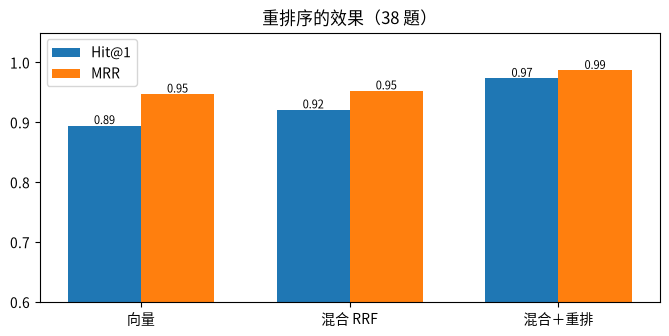

In [13]:
labels = list(results)
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(labels))
for n, m in enumerate(["Hit@1", "MRR"]):
    bars = ax.bar(x + (n - 0.5) * 0.35, [results[l][m] for l in labels], 0.35, label=m)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(x, labels)
ax.set_ylim(0.6, 1.05)
ax.legend()
ax.set_title(f"重排序的效果（{len(qa)} 題）")
plt.show()

## 試試看

1. 把候選數從 20 改成 5 和 50，重跑 Step 6。準確率與每題秒數怎麼變？
2. 在 `rerank` 加一個門檻：分數低於 0 的段落直接丟掉。問「海風科技的執行長是誰？」時，還剩幾塊？（這就是投影片「噪聲切片」的解法）
3. 文件轉問答（doc-to-QA）：請 LLM 為 `svc-tidepay` 的每個小節各寫 2 個「同事可能會問的問題」，把問題也存進 Chroma、metadata 指回原小節。再問一次 Step 7 的口語問題。

## 小結

- cross-encoder 把問題和段落一起讀，能分辨「像」和「答得了」；代價是慢，所以只重排召回後的 20 塊。
- 查詢改寫、HyDE 處理「問題寫得不像文件」，small-to-big 處理「找得準但上下文不夠」；都要多花一點時間或一次 LLM 呼叫，用題庫決定值不值得。
- 到這裡管線的每一格都有了。下一本 Lab 3-06 是本模組的 Lab 3：把基線和最佳組合放在同一份題庫上，連回答品質一起評估。